In [1]:
#| label: import
library(sets)       # power sets (Exercise 1)
library(combinat)   # permutations (Exercise 1)
library(ranger)     # random forest (Exercise 3)
library(randomForest)  # random forest for the LIME explainer (Exercise 4)
library(DALEX)      # model explainers (Exercise 4)
library(DALEXtra)   # LIME interface (Exercise 4)

set.seed(123456)


Attaching package: ‘combinat’




The following object is masked from ‘package:utils’:

    combn




randomForest 4.7-1.2



Type rfNews() to see new features/changes/bug fixes.




Attaching package: ‘randomForest’




The following object is masked from ‘package:ranger’:

    importance




Welcome to DALEX (version: 2.5.4).
Find examples and detailed introduction at: http://ema.drwhy.ai/




## Solution 1: The Shapley value

In [2]:
#| label: payoff
### Define the payoff function.
payoff = function(coalition) {
  ### Define boolean variables that indicate whether Timnit, Margret, Samy, Jeff
  ### and Larry are in the set or not.
  t = 't' %in% coalition
  s = 's' %in% coalition
  m = 'm' %in% coalition
  j = 'j' %in% coalition
  l = 'l' %in% coalition

  ### Definition of the payoff as given in the task.
  10*t + 10*m + 10*s + 2*j + 20*(t & m) + 20*(t & m & s) - 30*((t | m | s) & j)
}

### Testing, including the corner cases empty set and full population.
population = c('j', 'l', 'm', 's', 't')
payoff(c('t', 'm'))
payoff(c('t', 'j', 's'))
payoff(c())
payoff(population)

[1] 40

[1] -8

[1] 0

[1] 42

In [3]:
#| label: all-unique-subsets
all_unique_subsets = function(population) {
  ### Use the built-in set_power function and convert to a list for further processing.
  as.list(set_power(population))
}

### Testing
print(all_unique_subsets(c()))
print(all_unique_subsets(c(2, 4)))
print(all_unique_subsets(population))

[[1]]
{}



[[1]]
{}

[[2]]
{2}

[[3]]
{4}

[[4]]
{2, 4}



[[1]]
{}

[[2]]
{"j"}

[[3]]
{"l"}

[[4]]
{"m"}

[[5]]
{"s"}

[[6]]
{"t"}

[[7]]
{"j", "l"}

[[8]]
{"j", "m"}

[[9]]
{"j", "s"}

[[10]]
{"j", "t"}

[[11]]
{"l", "m"}

[[12]]
{"l", "s"}

[[13]]
{"l", "t"}

[[14]]
{"m", "s"}

[[15]]
{"m", "t"}

[[16]]
{"s", "t"}

[[17]]
{"j", "l", "m"}

[[18]]
{"j", "l", "s"}

[[19]]
{"j", "l", "t"}

[[20]]
{"j", "m", "s"}

[[21]]
{"j", "m", "t"}

[[22]]
{"j", "s", "t"}

[[23]]
{"l", "m", "s"}

[[24]]
{"l", "m", "t"}

[[25]]
{"l", "s", "t"}

[[26]]
{"m", "s", "t"}

[[27]]
{"j", "l", "m", "s"}

[[28]]
{"j", "l", "m", "t"}

[[29]]
{"j", "l", "s", "t"}

[[30]]
{"j", "m", "s", "t"}

[[31]]
{"l", "m", "s", "t"}

[[32]]
{"j", "l", "m", "s", "t"}



In [4]:
#| label: shapley-helpers
### A function which returns a list of all possible coalitions (represented as
### sets) without (one or more) specific members.
all_coalitions_without_members = function(members, population) {
  population_without_members = setdiff(population, members)
  as.list(all_unique_subsets(population_without_members))
}

### The payoff difference of adding a member to one coalition / to a list of
### coalitions. The v_function argument makes these reusable for arbitrary games.
payoff_diff = function(member, coalition, v_function = payoff) {
  v_function(c(member, coalition)) - v_function(coalition)
}

payoff_diff_list = function(member, coalitions, v_function = payoff) {
  sapply(1:length(coalitions), function(i) payoff_diff(member, coalitions[[i]], v_function))
}

### All Shapley values of a population, and a test function that prints them
### and also compares their sum to the total payoff (efficiency axiom).
all_shapley_values = function(population, shapley_fct, v_function = payoff) {
  sapply(1:length(population), function(i) shapley_fct(population[i], population, v_function))
}

shapley_test = function(population, shapley_fct, v_function = payoff) {
  shapley_values = all_shapley_values(population, shapley_fct, v_function)
  print(shapley_values)
  sum_ = sum(shapley_values)
  print(sum_)
  print(v_function(population))
  print(sum_ == v_function(population))
}

In [5]:
#| label: shapley-set
### Calculate the Shapley value for a player using the set definition.
shapley_set = function(member, population, v_function = payoff) {
  population = population[!duplicated(population)] # remove double elements
  all_coalitions_without_member = all_coalitions_without_members(member, population)

  ### Compute the payoff differences with and without the member player for
  ### all coalitions at once.
  payoff_diffs = payoff_diff_list(member, all_coalitions_without_member, v_function)

  ### Calculate the weights, which are the combinatorical number of
  ### occurrences of each set.
  F = length(population)
  weights = sapply(1:length(all_coalitions_without_member), function(i) {
    cardinality_coalition = length(all_coalitions_without_member[[i]])
    factorial(cardinality_coalition) * factorial(F - cardinality_coalition - 1) / factorial(F)
  })

  ### The Shapley value now is the weighted sum of the differences.
  sum(weights * payoff_diffs)
}

### Testing and sanity check (the last line checks the efficiency axiom).
print(shapley_set("t", population))
shapley_test(population, shapley_set)

[1] 24.16667


[1] -20.50000   0.00000  24.16667  14.16667  24.16667
[1] 42
[1] 42
[1] TRUE


In [6]:
#| label: shapley-perm
### Calculate a Shapley value using the permutation-based definition.
shapley_perm = function(member, population, v_function = payoff) {
  ### Generate all permutations from the population (as list of vectors).
  all_perms = combinat::permn(population)

  ### Find the index of the member player for every permutation.
  member_idxs = sapply(all_perms, function(x) match(member, x))

  ### Get the coalition for each permutation (which are just all the players
  ### with an index lower than the member player).
  coalitions = lapply(1:factorial(length(population)), function(i) all_perms[[i]][1:member_idxs[i] - 1])

  ### The Shapley value is the mean of all the payoff differences.
  differences = payoff_diff_list(member, coalitions, v_function)
  mean(differences)
}

### Testing
shapley_test(population, shapley_perm)

[1] -20.50000   0.00000  24.16667  14.16667  24.16667
[1] 42
[1] 42
[1] TRUE


In [7]:
#| label: shapley-perm-approx
### Calculate the permutation-based approximation of the Shapley value with
### num_iter iterations.
shapley_perm_approx = function(member, population, v_function = payoff, num_iter = 100) {
  ### Sample num_iter permutations (the single columns are the permutations).
  perms = replicate(num_iter, sample(population))

  ### Find the index of the member player in every permutation (column).
  member_idxs = apply(perms, 2, function(x) match(member, x))

  ### Get the coalition for each permutation (all players before the member).
  coalitions = lapply(1:num_iter, function(i) perms[1:member_idxs[i] - 1, i])

  ### The estimate is the mean of the payoff differences over all sampled
  ### coalitions, same as for the exact order definition.
  differences = payoff_diff_list(member, coalitions, v_function)
  mean(differences)
}

### Testing: convergence for a growing number of iterations.
for (i in 2:4) {
  print(shapley_perm_approx('t', population, num_iter = 10^i))
}
shapley_test(population, shapley_perm_approx)

[1] 23.6
[1] 25.09
[1] 24.64


[1] -21.4   0.0  26.3  13.1  24.5
[1] 42.5
[1] 42
[1] FALSE


In [8]:
#| label: axiom-checks
### Symmetry: if the premise (equal payoff differences for all coalitions
### without j and k) holds, the Shapley values of j and k must be identical;
### if the premise is violated, the axiom holds vacuously.
symmetry_check = function(j, k, population) {
  all_coalitions_without_candidates = all_coalitions_without_members(c(j, k), population)
  payoff_diff_j = payoff_diff_list(j, all_coalitions_without_candidates)
  payoff_diff_k = payoff_diff_list(k, all_coalitions_without_candidates)
  all(any(payoff_diff_j != payoff_diff_k) | shapley_set(j, population) == shapley_set(k, population))
}

### Check the symmetry property for all possible combinations of two players.
all_combinations_two_players = as.list(set_combn(population, m = 2))
symmetry_check_all_combinations = sapply(1:length(all_combinations_two_players),
  function(i) symmetry_check(as.list(all_combinations_two_players[[i]])[1],
                             as.list(all_combinations_two_players[[i]])[2],
                             population))
print(all(symmetry_check_all_combinations))

### Dummy: a player whose payoff differences are all 0 must have Shapley value 0.
dummy_check = function(j, population) {
  all_coalitions_without_candidate = all_coalitions_without_members(j, population)
  payoff_diff_j = payoff_diff_list(j, all_coalitions_without_candidate)
  all(any(payoff_diff_j != 0) | shapley_set(j, population) == 0)
}

print(all(sapply(1:length(population), function(i) dummy_check(population[i], population))))

### Additivity: the Shapley values of the sum of two games are the sums of
### the games' Shapley values (rounding guards against numerical noise).
additivity_check = function(population, payoff_func_1, payoff_func_2) {
  payoff_func_1_and_2 = function(x) payoff_func_1(x) + payoff_func_2(x)
  all_shapley_values_payoff_func_1 = all_shapley_values(population, shapley_set, payoff_func_1)
  all_shapley_values_payoff_func_2 = all_shapley_values(population, shapley_set, payoff_func_2)
  all_shapley_values_payoff_func_1_and_2 = all_shapley_values(population, shapley_set, payoff_func_1_and_2)
  all(round(all_shapley_values_payoff_func_1_and_2, 5)
    == round(all_shapley_values_payoff_func_1 + all_shapley_values_payoff_func_2, 5))
}

### Test with a decomposition of the original payoff into its first three and
### its remaining summands.
payoff_func_1 = function(coalition) {
  t = 't' %in% coalition; s = 's' %in% coalition; m = 'm' %in% coalition
  j = 'j' %in% coalition; l = 'l' %in% coalition
  10*t + 10*m + 10*s + 2*j
}
payoff_func_2 = function(coalition) {
  t = 't' %in% coalition; s = 's' %in% coalition; m = 'm' %in% coalition
  j = 'j' %in% coalition; l = 'l' %in% coalition
  20*(t & m) + 20*(t & m & s) - 30*((t | m | s) & j)
}
print(additivity_check(population, payoff_func_1, payoff_func_2))

### Efficiency: the Shapley values must sum to the payoff of the full population.
efficiency_check = function(population, v_function = payoff) {
  v_function(population) == sum(all_shapley_values(population, shapley_set, v_function))
}
print(efficiency_check(population))

[1] TRUE


[1] TRUE


[1] TRUE


[1] TRUE


## Solution 2: Axioms of Shapley Values

(Theory exercise, no code.)

## Solution 3: SHAP

In [9]:
#| label: fifa-data
### Read the dataset via the read.csv()-function.
df = read.csv(file = "../data/fifa.csv")

### Transform the character variable Man.of.the.Match ("Yes"/"No") into a
### logical variable. This has to happen before deleting all character
### variables, else we would remove our target variable as well.
df$Man.of.the.Match = ifelse(df$Man.of.the.Match == "Yes", TRUE, FALSE)

### Remove all variables of type character.
df = df[, !sapply(df, is.character)]

### Delete all columns containing at least one NA value.
df = df[, apply(df, 2, function(x) !any(is.na(x)))]

### Classical training and testing split.
train_idx = sample(nrow(df), 0.7 * nrow(df))
training_data = df[train_idx, ]
test_data = df[-train_idx, ]

### Split into features and target, which will be used later on.
X_train = training_data[, -which(names(training_data) == "Man.of.the.Match")]
X_test = test_data[, -which(names(test_data) == "Man.of.the.Match")]
y_train = training_data$Man.of.the.Match
y_test = test_data$Man.of.the.Match

### Model a random forest using the ranger package (others are possible too).
classifier_RF = ranger(Man.of.the.Match ~ ., training_data)
print(classifier_RF)

### Exemplary predictions for instances from the test set.
predict(classifier_RF, X_test[1:5, ])$predictions

Ranger result

Call:
 ranger(Man.of.the.Match ~ ., training_data) 

Type:                             Classification 
Number of trees:                  500 
Sample size:                      89 
Number of independent variables:  18 
Mtry:                             4 
Target node size:                 1 
Variable importance mode:         none 
Splitrule:                        gini 
OOB prediction error:             24.72 % 


[1] 1 1 1 1 1

In [10]:
#| label: marginal-vfunc
### The marginal sampling-based SHAP value function, a Monte-Carlo
### approximation of the PD-function evaluated at `observation`.
marginal_vfunc = function(S, observation, X, model, nr_samples = 100) {
  ### Get nr_samples random observations from the given dataset.
  X_tmp = X[sample(nrow(X), nr_samples, replace = TRUE), ]

  ### Replace the features given in S by the values of the observation.
  X_tmp[, S] = observation[, S]

  ### Predict and average.
  mean(predict(model, X_tmp)$predictions)
}

### Testing on different feature subsets.
marginal_vfunc(names(X_train)[1:3], X_test[1, ], X_train, classifier_RF, nr_samples = 1000)
marginal_vfunc(names(X_train)[1], X_test[1, ], X_train, classifier_RF, nr_samples = 1000)
marginal_vfunc(names(X_train)[1:2], X_test[1, ], X_train, classifier_RF, nr_samples = 1000)
marginal_vfunc(names(X_train)[1:2], X_test[2, ], X_train, classifier_RF, nr_samples = 1000)

[1] 0.515

[1] 0.541

[1] 0.525

[1] 0.651

In [11]:
#| label: shapley-approx-shap
### Wrap the value function so that it only depends on the coalition; the
### Shapley implementations from Exercise 1 can then be reused directly.
model_specific_marginal_vfunc = function(coalition) {
  marginal_vfunc(coalition, X_test[1, ], X_train, classifier_RF, nr_samples = 100)
}

print(shapley_perm_approx(names(X_test)[3], names(X_test),
  v_function = model_specific_marginal_vfunc))
shapley_test(names(X_test), shapley_perm_approx, v_function = model_specific_marginal_vfunc)

[1] -0.018


 [1]  0.1223 -0.0057 -0.0263 -0.0125  0.0437  0.0499 -0.0648  0.1787  0.0900
[10] -0.0185 -0.0304  0.1344  0.1050 -0.0134  0.0021  0.0019  0.0019  0.0023
[1] 0.5606
[1] 1
[1] FALSE


In [12]:
#| label: shap-functions
### Sample for every entry in our data whether to include it or not.
sample_mask = function(nrow, ncol) {
  matrix(rbinom(nrow * ncol, 1, 0.5), nrow = nrow)
}

### The Shapley kernel weights pi_x(|z'|), where |z'| is the number of
### included features (given by a 1 in the mask).
shap_weights = function(mask) {
  p = ncol(mask)
  z_prime_abs = rowSums(mask)
  (p - 1) / (choose(p, z_prime_abs) * z_prime_abs * (p - z_prime_abs))
}

### Create the dataset generated during the SHAP calculations: nr_samples
### background samples, where the positions with mask == 1 are replaced by
### the values of the given observation obs.
replace_dataset = function(obs, X, n_samples, mask) {
  X_new = X[sample(nrow(X), n_samples, replace = TRUE), ]
  obs_rep = obs[rep(1, n_samples), ]

  ### At positions where the mask is 1 we effectively replace the original
  ### entries by the ones of the observation.
  X_sample = X_new - mask * (X_new - obs_rep)
  X_sample
}

### Putting things together: the sampling-based Kernel SHAP function.
kernel_shap = function(obs, X, n_samples, model) {
  mask = sample_mask(n_samples, ncol(X))
  df = replace_dataset(obs, X, n_samples, mask)
  weights = shap_weights(mask)
  pred = predict(model, df)$predictions

  ### Save the mask as well as the respective predictions.
  df_shap = as.data.frame(mask)
  names(df_shap) = names(X)
  df_shap$pred = pred

  ### Fit a weighted linear model using the above calculated weights. Since
  ### we are in a binary setting, we perform logistic regression.
  wls_model = suppressWarnings(
    glm(pred ~ ., family = binomial, data = df_shap, weights = weights))
  wls_model$coefficients
}

In [13]:
#| label: kernel-shap-run
### Calculate the KernelSHAP values for the first instance of the test set.
obs = X_test[1, ]
shap_vals = kernel_shap(obs, X_train, 1000, classifier_RF)
shap_vals

(Intercept)            Goal.Scored      Ball.Possession.. 
           -0.51433283             0.95296140            -0.24178557 
              Attempts              On.Target             Off.Target 
           -1.13861019             0.22125218             0.93288702 
               Blocked                Corners               Offsides 
            0.37758708            -0.89363307             0.70540957 
            Free.Kicks                  Saves        Pass.Accuracy.. 
            0.48792946            -0.56021949             0.07131671 
                Passes Distance.Covered..Kms.        Fouls.Committed 
            0.87191526             0.67144100            -0.27271841 
           Yellow.Card           Yellow...Red                    Red 
            0.09941288            -0.08898443             0.20946664 
          Goals.in.PSO 
           -0.36510444

## Solution 4: LIME

Preparation of a new explainer is initiated
  -> model label       :  Random Forest 
  -> data              :  89  rows  18  cols 
  -> target variable   :  89  values 
  -> predict function  :  yhat.randomForest  will be used (  default  )
  -> predicted values  :  No value for predict function target column. (  default  )
  -> model_info        :  package randomForest , ver. 4.7.1.2 , task classification (  default  ) 
  -> predicted values  :  numerical, min =  0.028 , mean =  0.4683146 , max =  0.938  
  -> residual function :  difference between y and yhat (  default  )
  -> residuals         :  numerical, min =  -0.346 , mean =  0.003595506 , max =  0.318  
  A new explainer has been created!  


Warning message:
“Yellow...Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Goals.in.PSO does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


Warning message:
“`aes_()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`
ℹ The deprecated feature was likely used in the lime package.
  Please report the issue at <https://github.com/tidymodels/lime/issues>.”


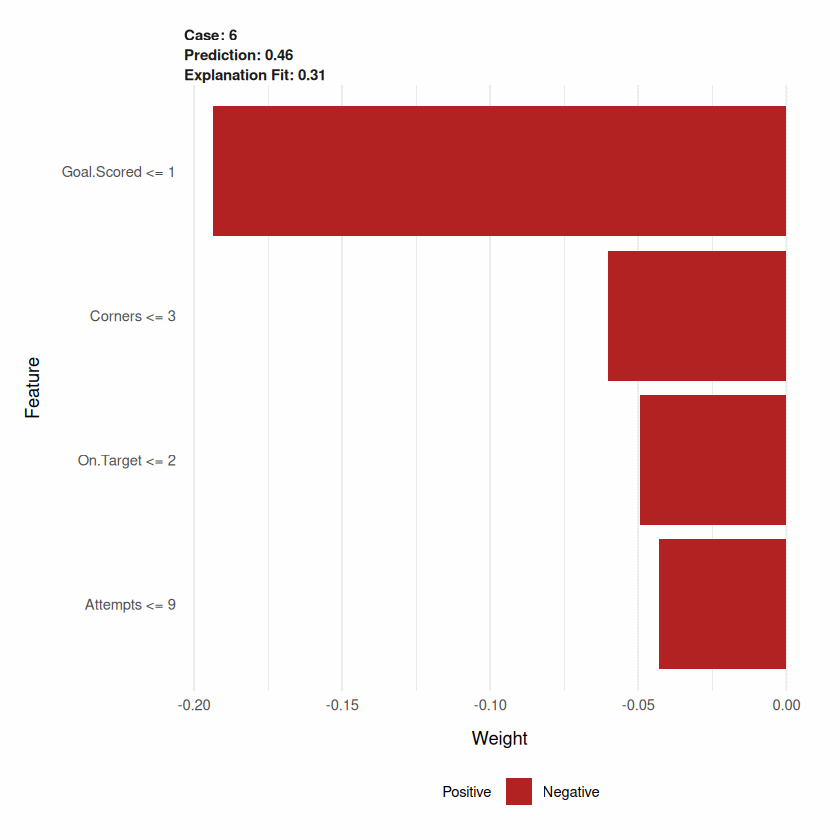

In [14]:
#| label: lime-explain
### Fit a random forest with the randomForest package (the DALEX LIME
### interface expects a classification model here).
rf_model = randomForest(as.factor(Man.of.the.Match) ~ ., training_data)

model_ex = DALEX::explain(model = rf_model,
  data = X_train,
  y = as.numeric(y_train),
  label = "Random Forest")

### Local explanations for the model via LIME.
model_type.dalex_explainer = DALEXtra::model_type.dalex_explainer
predict_model.dalex_explainer = DALEXtra::predict_model.dalex_explainer

iml_obs = predict_surrogate(explainer = model_ex,
  new_observation = X_test[1, ],
  type = "lime")

plot(iml_obs)

Warning message:
“Yellow...Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Goals.in.PSO does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


Warning message:
“Yellow...Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Red does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message:
“Goals.in.PSO does not contain enough variance to use quantile binning. Using standard binning instead.”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


Warning message in gower_work(x = x, y = y, pair_x = pair_x, pair_y = pair_y, n = NULL, :
“skipping variable with zero or non-finite range”


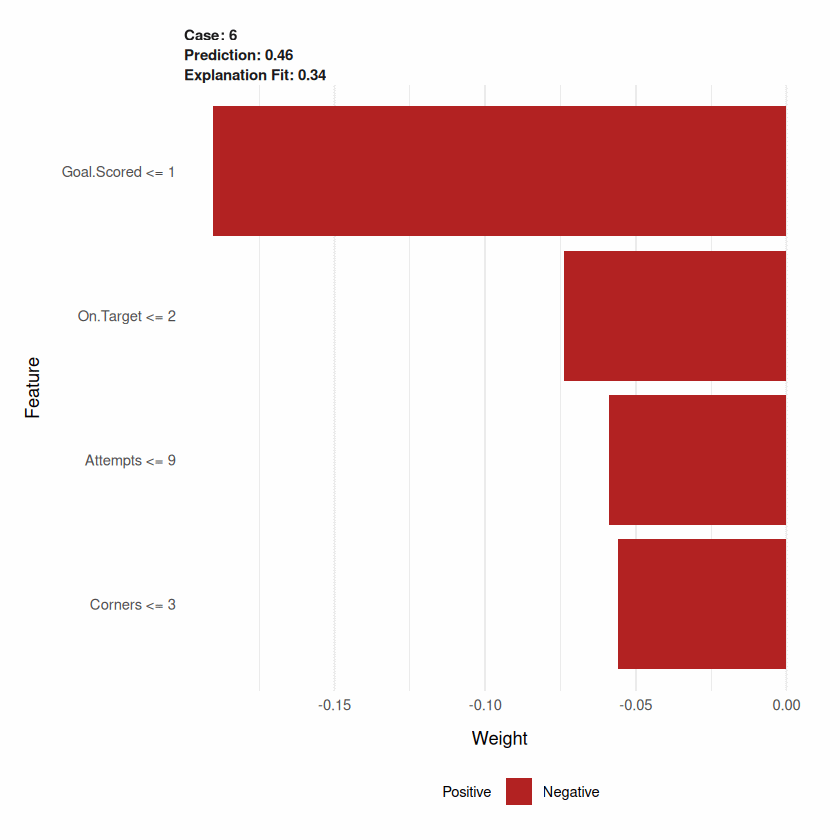

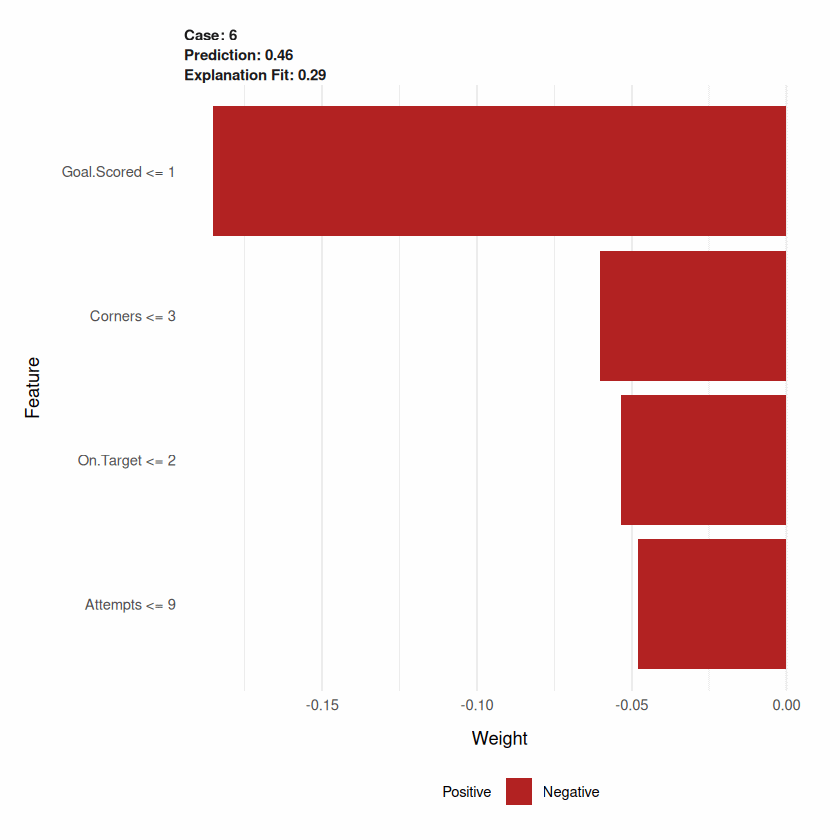

In [15]:
#| label: lime-kernel-width
### Set the kernel width to 10.
iml_obs = predict_surrogate(explainer = model_ex,
  new_observation = X_test[1, ],
  type = "lime",
  kernel_width = 10)
plot(iml_obs)

### Set the kernel width to 0.001.
iml_obs = predict_surrogate(explainer = model_ex,
  new_observation = X_test[1, ],
  type = "lime",
  kernel_width = 0.001)
plot(iml_obs)